# 01 — Exploratory Data Analysis (EDA)

**Projekt:** Predictive Maintenance MLOps Demo
**Adat:** Szintetikus ipari szenzoradat (NASA CMAPSS struktúra)
**Cél:** Az adathalmaz megértése modelltanítás előtt.

## Tartalom
1. Setup és importok
2. Adatbetöltés
3. Alap áttekintés
4. Hiányzó értékek
5. Célváltozó eloszlása
6. Szenzor statisztikák
7. Idősor vizualizáció
8. Anomaly vs normál
9. Korreláció
10. Összefoglaló

In [2]:
# --- Standard library ---
from pathlib import Path

# --- Data handling ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Settings ---
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["figure.dpi"] = 100

# --- Reproduceability ---
RANDOM_STATE = 42

print("Environment is done.")

Environment is done.


In [3]:
# --- Load the data ---
DATA_PATH = Path("../data/raw/sensor_data.csv")

df = pd.read_csv(DATA_PATH)

print(f"Loaded: {DATA_PATH}")
print(f"Shape:    {df.shape}")
print(f"Columns: {list(df.columns)}")

Loaded: ..\data\raw\sensor_data.csv
Shape:    (25780, 24)
Columns: ['unit', 'cycle', 's1', 's2', 's3', 's4', 's5', 's6', 's7', 's8', 's9', 's10', 's11', 's12', 's13', 's14', 's15', 's16', 's17', 's18', 's19', 's20', 's21', 'anomaly']


In [ ]:
# --- First some rows (Headers) ---
df.head()

# --- Data type and non-null values ---
df.info()

# --- Statistical overview ---
df.describe().T

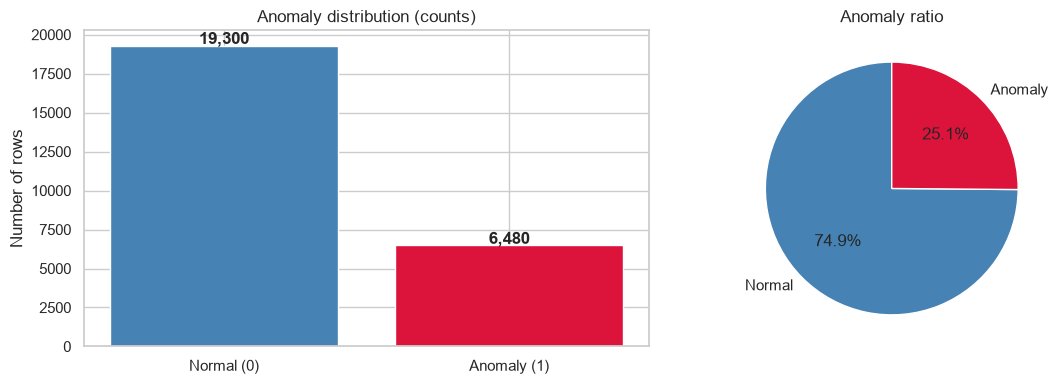

In [11]:
# --- Anomaly distribution ---
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Count plot
counts = df["anomaly"].value_counts().sort_index()
axes[0].bar(["Normal (0)", "Anomaly (1)"], counts.values, color=["steelblue", "crimson"])
axes[0].set_title("Anomaly distribution (counts)")
axes[0].set_ylabel("Number of rows")
for i, v in enumerate(counts.values):
    axes[0].text(i, v + 100, f"{v:,}", ha="center", fontweight="bold")

# Ratio
axes[1].pie(counts.values, labels=["Normal", "Anomaly"], autopct="%1.1f%%",
            colors=["steelblue", "crimson"], startangle=90)
axes[1].set_title("Anomaly ratio")

plt.tight_layout()
plt.show()

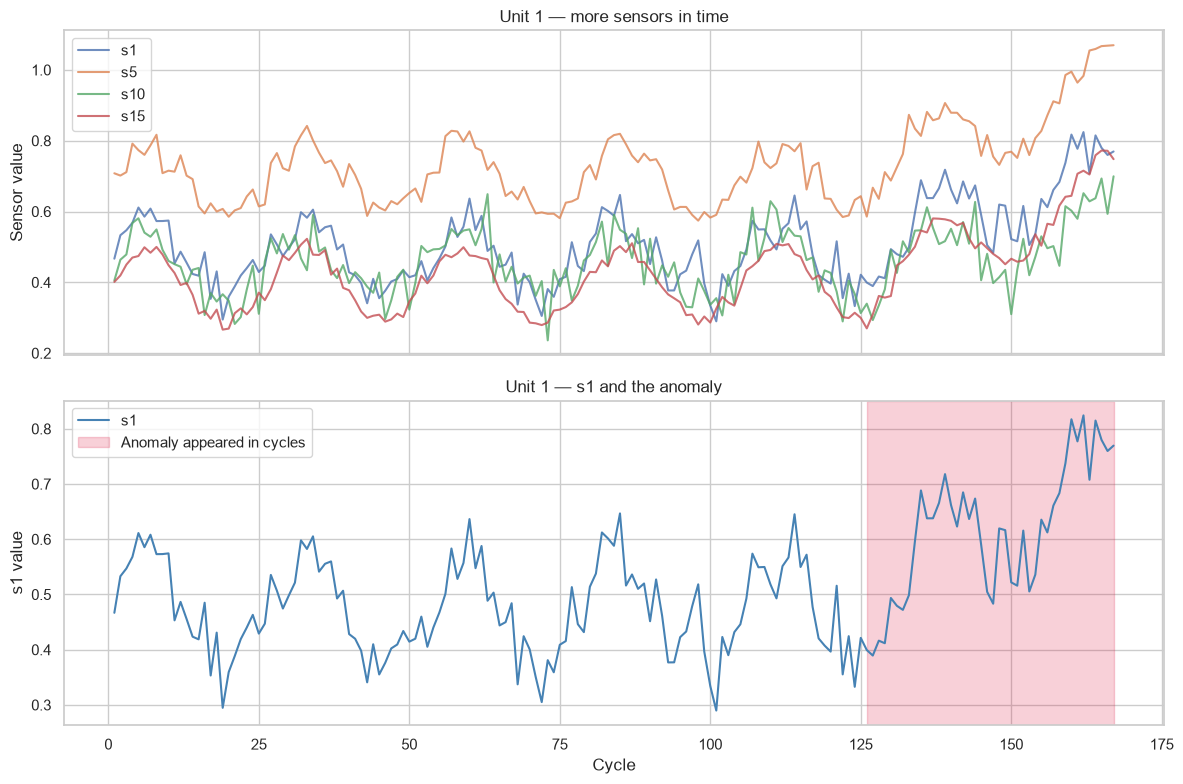

Unit 1: 167 cycle, anomaly starts at: 126


In [15]:
# --- One Unit sensor data ---
sample_unit = 1
unit_df = df[df["unit"] == sample_unit]

fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)

# More sensor's data in time
for s in ["s1", "s5", "s10", "s15"]:
    axes[0].plot(unit_df["cycle"], unit_df[s], label=s, alpha=0.8)
axes[0].set_title(f"Unit {sample_unit} — more sensors in time")
axes[0].set_ylabel("Sensor value")
axes[0].legend(loc="upper left")

# Anomaly part highlighting
axes[1].plot(unit_df["cycle"], unit_df["s1"], label="s1", color="steelblue")
anomaly_start = unit_df[unit_df["anomaly"] == 1]["cycle"].min()
axes[1].axvspan(anomaly_start, unit_df["cycle"].max(), alpha=0.2, color="crimson",
                label="Anomaly appeared in cycles")
axes[1].set_title(f"Unit {sample_unit} — s1 and the anomaly")
axes[1].set_xlabel("Cycle")
axes[1].set_ylabel("s1 value")
axes[1].legend(loc="upper left")

plt.tight_layout()
plt.show()

print(f"Unit {sample_unit}: {len(unit_df)} cycle, anomaly starts at: {anomaly_start}")

In [17]:
# --- Anomaly vs normal: sensors statistics ---
sensor_cols = [c for c in df.columns if c.startswith("s")]

# Individual statistics for both groups
normal_stats = df[df["anomaly"] == 0][sensor_cols].agg(["mean", "std"]).T
normal_stats.columns = ["Normal_mean", "Normal_std"]

anomaly_stats = df[df["anomaly"] == 1][sensor_cols].agg(["mean", "std"]).T
anomaly_stats.columns = ["Anomaly_mean", "Anomaly_std"]

# Concatenation
stats = normal_stats.join(anomaly_stats)

# Differennce (effect size-like indicator)
stats["mean_diff"] = stats["Anomaly_mean"] - stats["Normal_mean"]
stats["abs_diff"] = stats["mean_diff"].abs()

# Sort by strongest indicators
stats_sorted = stats.sort_values("abs_diff", ascending=False)

print("Sensors sorted by the average difference between anomaly and normal states:")
print(stats_sorted[["Normal_mean", "Anomaly_mean", "mean_diff"]].round(4))

Sensors sorted by the average difference between anomaly and normal states:
     Normal_mean  Anomaly_mean  mean_diff
s9        0.5075        0.6131     0.1056
s7        0.4992        0.6028     0.1035
s12       0.4943        0.5973     0.1029
s21       0.5143        0.6170     0.1026
s10       0.5040        0.6065     0.1025
s8        0.4988        0.6013     0.1025
s15       0.4979        0.6004     0.1025
s3        0.5182        0.6198     0.1016
s17       0.4996        0.6004     0.1008
s4        0.4978        0.5979     0.1001
s20       0.4899        0.5900     0.1000
s2        0.4933        0.5931     0.0998
s14       0.5030        0.6021     0.0991
s13       0.5022        0.6007     0.0985
s18       0.5025        0.6007     0.0982
s5        0.5053        0.6030     0.0977
s1        0.5139        0.6097     0.0958
s19       0.5022        0.5969     0.0947
s6        0.5055        0.5995     0.0940
s16       0.4951        0.5880     0.0929
s11       0.5085        0.6011     0.0926


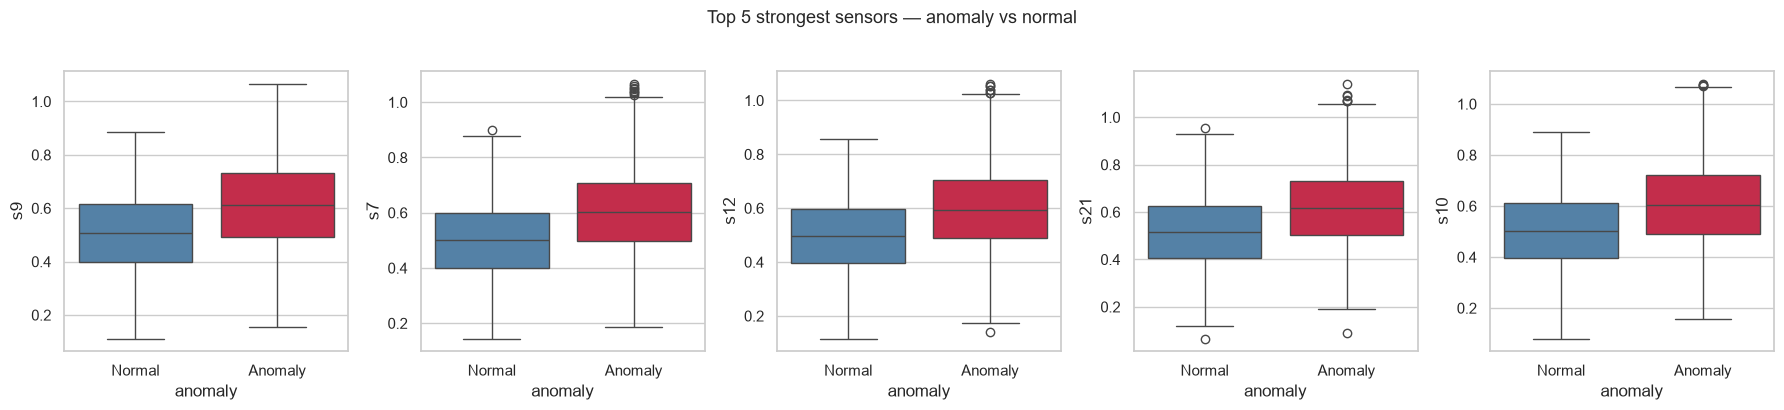

In [ ]:
# --- Boxplot: top 5 sensors - anomaly vs normal ---
top5 = stats_sorted.head(5).index.tolist()

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
for ax, sensor in zip(axes, top5):
    sns.boxplot(data=df, x="anomaly", y=sensor, ax=ax, hue="anomaly", palette=["steelblue", "crimson"], legend=False)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["Normal", "Anomaly"])
    ax.set_xticklabels(["Normal", "Anomaly"])

plt.suptitle("Top 5 strongest sensors — anomaly vs normal", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

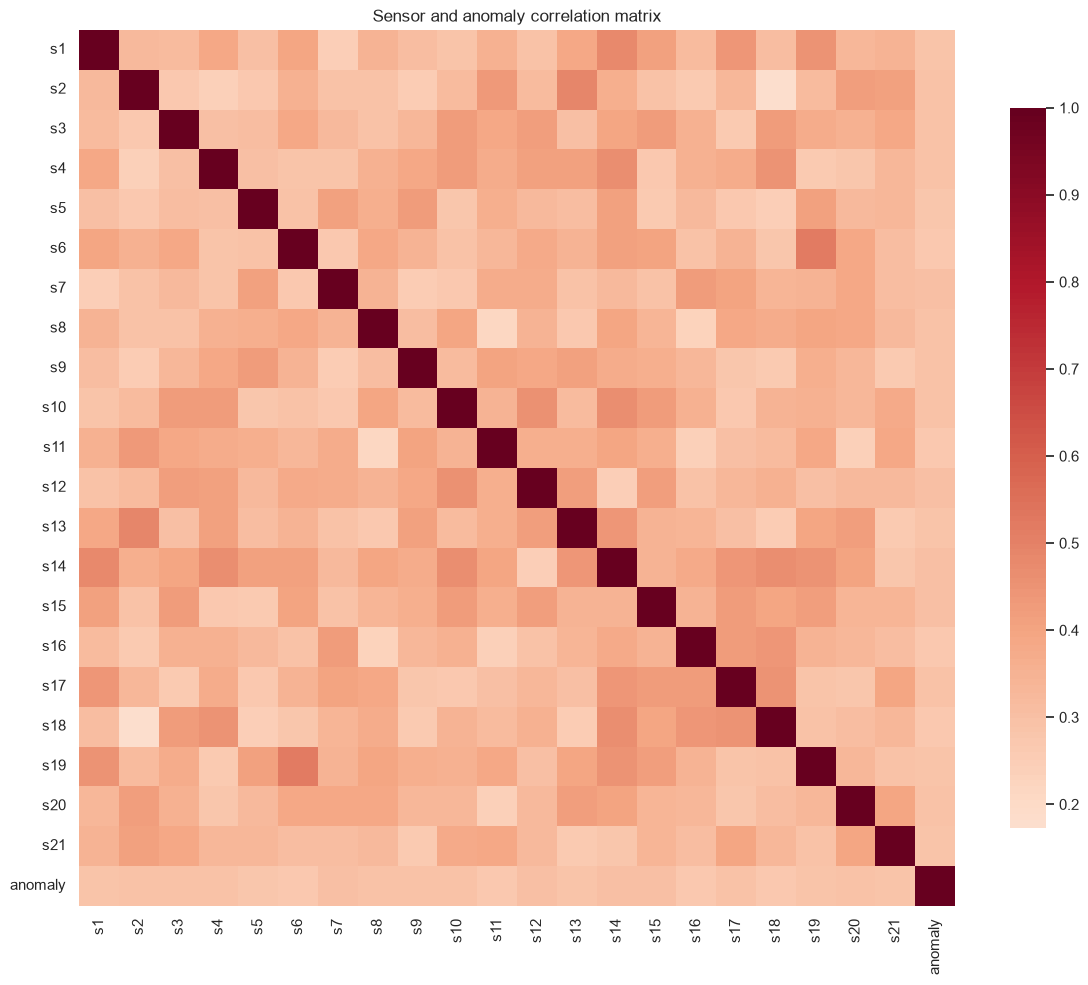

Correlation with the 'anomaly' label (sorted by absolute value):
s14    0.3043
s7     0.3042
s12    0.3031
s15    0.3001
s3     0.2943
s8     0.2928
s9     0.2922
s17    0.2921
s20    0.2919
s4     0.2913
s2     0.2903
s10    0.2898
s1     0.2889
s13    0.2882
s21    0.2882
s19    0.2836
s5     0.2771
s11    0.2748
s6     0.2733
s16    0.2709
s18    0.2685
Name: anomaly, dtype: float64


In [22]:
# --- Correlation matrix ---
corr = df[sensor_cols + ["anomaly"]].corr()

fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=False, square=True,
            cbar_kws={"shrink": 0.8}, ax=ax)
ax.set_title("Sensor and anomaly correlation matrix")
plt.tight_layout()
plt.show()

# Correlation with anomaly, sorted
print("Correlation with the 'anomaly' label (sorted by absolute value):")
corr_with_anomaly = corr["anomaly"].drop("anomaly").abs().sort_values(ascending=False)
print(corr_with_anomaly.round(4))

## Összefoglaló — EDA következtetések

### Adathalmaz
- **25,780 sor, 24 oszlop**: 2 azonosító (`unit`, `cycle`), 21 szenzor, 1 címke (`anomaly`)
- **Nincs hiányzó érték** - nincs szükség imputációra
- **100 egység**, egyenként 150-350 ciklus

### Célváltozó
- **25.1% anomaly** — enyhe imbalance, de nem extrém
- A modellnél `class_weight="balanced"` javasolt

### Szenzorok
- Minden szenzornak van szórása → mind használható
- **Top jelzők**: s9, s7, s12, s21, s10 (mean_diff ~0.10-0.11)
- **Megfigyelés**: a szintetikus adatban minden szenzor **hasonló erősséggel** jelez, mert a degradáció uniform. Valódi ipari adatban ez szélsőségesebb lenne.
- Az anomaly szakaszban a szenzorok **eltolódnak felfelé** - ez a degradáció jele

### Következő lépések
1. **Train/val/test split**: unit szinten (nincs data leakage)
2. **Modell**: Isolation Forest (unsupervised baseline) + Logistic Regression (supervised baseline)
3. **Kiértékelés**: precision, recall, F1 - az accuracy félrevezető
4. **Feature engineering**: rolling statisztikák, különbségek (később)

### Döntések és trade-offok
- **Szintetikus adat**: kontrollált anomaly, reprodukálható, de uniform degradáció
- **21 szenzor**: mind megtartva az MVP-hez
- **Unit szintű split**: kritikus a data leakage elkerüléséhez